# Employee Attrition Prediction - Model Training


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              roc_curve, auc)
import pickle

sns.set_style('whitegrid')

In [5]:
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [7]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## 2. Understand the problem

In [8]:
print(df['Attrition'].value_counts())
print(df['Attrition'].value_counts(normalize=True) * 100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis

### 3.1 Attrition rate by OverTime

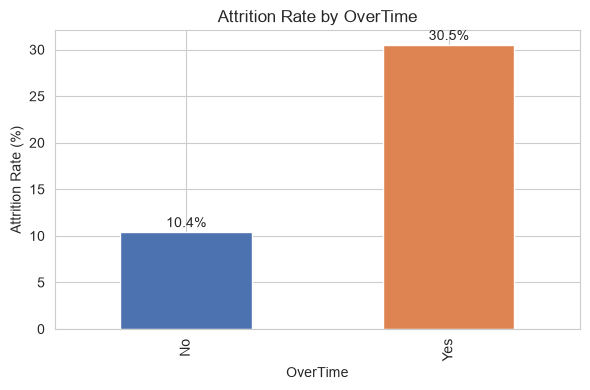

In [9]:
rate = df.groupby('OverTime')['Attrition'].apply(lambda s: (s == 'Yes').mean() * 100)
ax = rate.plot(kind='bar', color=['#4C72B0', '#DD8452'], figsize=(6, 4))
ax.set_ylabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by OverTime')
for i, v in enumerate(rate):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

### 3.2 Attrition rate by Department

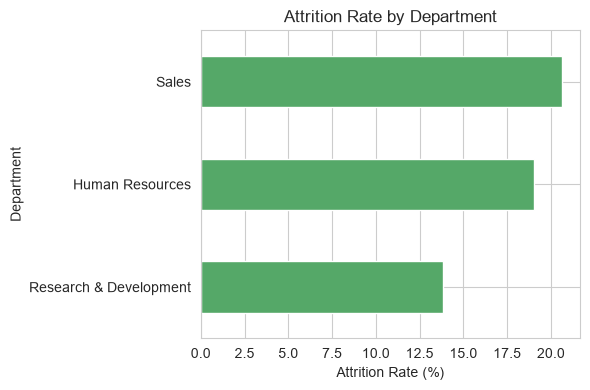

In [10]:
rate = df.groupby('Department')['Attrition'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()
ax = rate.plot(kind='barh', color='#55A868', figsize=(6, 4))
ax.set_xlabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by Department')
plt.tight_layout()
plt.show()

### 3.3 Monthly income: employees who left vs stayed

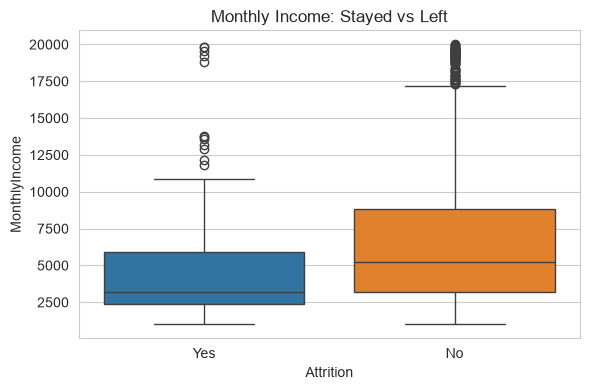

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', hue='Attrition', legend=False, ax=ax)
ax.set_title('Monthly Income: Stayed vs Left')
plt.tight_layout()
plt.show()

### 3.4 Correlation heatmap of numeric features

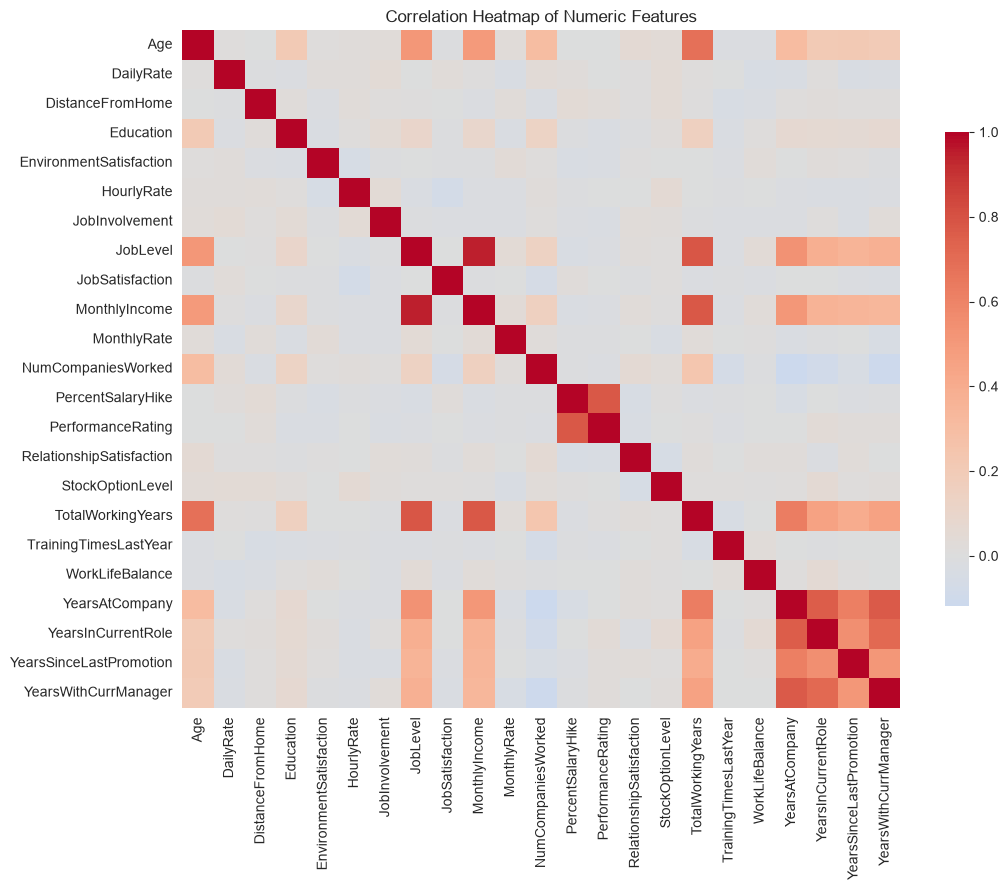

In [12]:
numdf = df.select_dtypes(include=[np.number]).drop(columns=['EmployeeCount', 'StandardHours', 'EmployeeNumber'], errors='ignore')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(numdf.corr(), cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

In [13]:
print(df[['EmployeeCount', 'Over18', 'StandardHours']].nunique())
df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64


## 4. Feature engineering

In [14]:
df['IncomePerYearAtCompany'] = df['MonthlyIncome'] / (df['YearsAtCompany'] + 1)
df['TenureRatio'] = df['YearsAtCompany'] / (df['TotalWorkingYears'] + 1)
df['PromotionGap'] = df['YearsAtCompany'] - df['YearsSinceLastPromotion']
df['IsFrequentTraveler'] = (df['BusinessTravel'] == 'Travel_Frequently').astype(int)

df[['IncomePerYearAtCompany', 'TenureRatio', 'PromotionGap', 'IsFrequentTraveler']].head()

,IncomePerYearAtCompany,TenureRatio,PromotionGap,IsFrequentTraveler
0,856.142857,0.666667,6,0
1,466.363636,0.909091,9,1
2,2090.000000,0.000000,0,0
3,323.222222,0.888889,5,1
4,1156.000000,0.285714,0,0


In [15]:
cat_cols = ['Attrition', 'BusinessTravel', 'Department', 'EducationField',
            'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

In [16]:
X = df.drop('Attrition', axis=1)
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (1176, 34)  Test: (294, 34)


## 5. Train and compare models



In [17]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=8),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', max_depth=10),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'macro_f1': f1_score(y_test, pred, average='macro'),
        'precision_leave': precision_score(y_test, pred, pos_label=1),
        'recall_leave': recall_score(y_test, pred, pos_label=1),
    }

results_df = pd.DataFrame(results).T
results_df

/Users/akshit/Downloads/employee_attrition_predictor 2/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,accuracy,macro_f1,precision_leave,recall_leave
Logistic Regression,0.734694,0.650959,0.349515,0.765957
Decision Tree,0.721088,0.575952,0.266667,0.425532
Random Forest,0.823129,0.631543,0.428571,0.319149


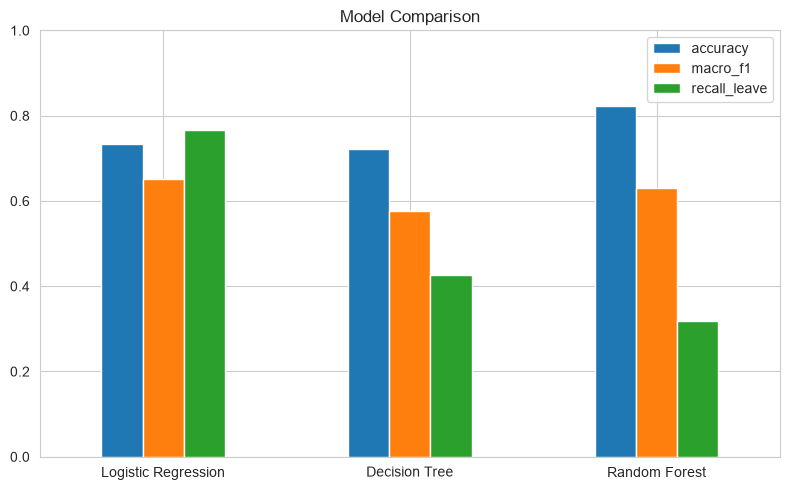

In [18]:
results_df[['accuracy', 'macro_f1', 'recall_leave']].plot(kind='bar', figsize=(8, 5))
plt.ylim(0, 1)
plt.title('Model Comparison')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Final model (Random Forest)

In [19]:
final_model = models['Random Forest']
pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, target_names=['Stayed', 'Left']))

              precision    recall  f1-score   support

      Stayed       0.88      0.92      0.90       247
        Left       0.43      0.32      0.37        47

    accuracy                           0.82       294
   macro avg       0.65      0.62      0.63       294
weighted avg       0.80      0.82      0.81       294



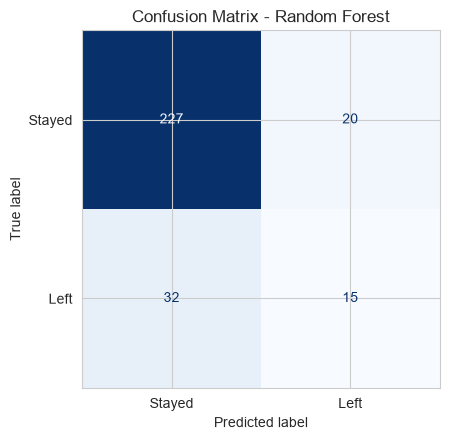

In [20]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Left']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - Random Forest')
plt.tight_layout()
plt.show()

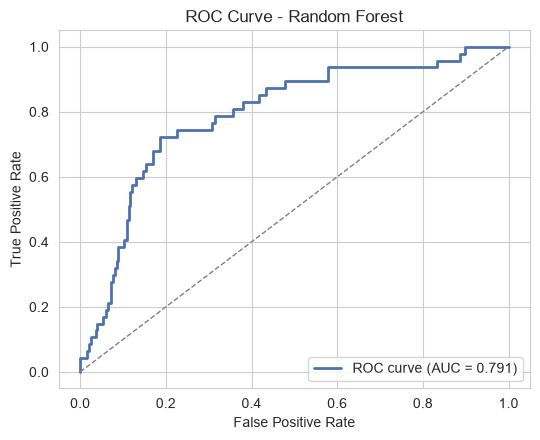

ROC AUC: 0.7914549056766302


In [21]:
fpr, tpr, _ = roc_curve(y_test, proba)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(fpr, tpr, color='#4C72B0', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Random Forest')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('ROC AUC:', roc_auc)

## 7. Feature importance

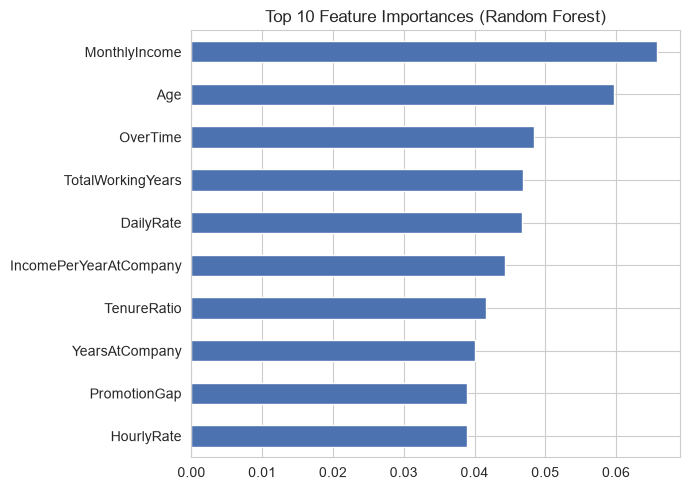

MonthlyIncome             0.065752
Age                       0.059739
OverTime                  0.048437
TotalWorkingYears         0.046906
DailyRate                 0.046668
IncomePerYearAtCompany    0.044328
TenureRatio               0.041644
YearsAtCompany            0.040061
PromotionGap              0.038964
HourlyRate                0.038941
dtype: float64

In [22]:
importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind='barh', figsize=(7, 5), color='#4C72B0')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()

importance.head(10)

In [23]:
with open('model.pkl', 'wb') as f:
    pickle.dump({
        'model': final_model,
        'encoders': encoders,
        'feature_columns': list(X.columns),
        'feature_importance': importance.head(8).to_dict(),
    }, f)

print('model saved as model.pkl')

model saved as model.pkl
